In [8]:
!pip install -q tensorflow-datasets scikit-learn

In [9]:
!pip install -q importlib_resources

In [10]:
import importlib_resources

print("Library installed successfully!")

Library installed successfully!


In [11]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("TensorFlow:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow: 2.21.0
Libraries imported successfully!


In [12]:
dataset, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True
)

print("Dataset loaded!")
print("Total images:", info.splits["train"].num_examples)
print("Number of classes:", info.features["label"].num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.COSWOW_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Dataset loaded!
Total images: 54303
Number of classes: 38


In [13]:
class_names = info.features["label"].names

healthy_ids = [
    i for i, name in enumerate(class_names)
    if "healthy" in name.lower()
]

print("Healthy category IDs:", healthy_ids)
print("Original categories:", len(class_names))

Healthy category IDs: [3, 4, 5, 9, 13, 17, 19, 21, 23, 24, 26, 30]
Original categories: 38


In [14]:
def prepare_image(image, label):

    image = tf.image.resize(image, (128, 128))

    is_healthy = tf.reduce_any(
        tf.equal(label, healthy_ids)
    )

    label = tf.cast(is_healthy, tf.float32)

    return image, label

In [15]:
total = info.splits["train"].num_examples

train_count = int(total * 0.70)
val_count = int(total * 0.15)

shuffled = dataset.shuffle(
    buffer_size=10000,
    seed=42,
    reshuffle_each_iteration=False
)

train_raw = shuffled.take(train_count)

remaining = shuffled.skip(train_count)

val_raw = remaining.take(val_count)
test_raw = remaining.skip(val_count)

print("Training images:", train_count)
print("Validation images:", val_count)
print("Testing images:", total - train_count - val_count)


Training images: 38012
Validation images: 8145
Testing images: 8146


In [16]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32

train_ds = (
    train_raw
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_raw
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_raw
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Images prepared successfully!")

Images prepared successfully!


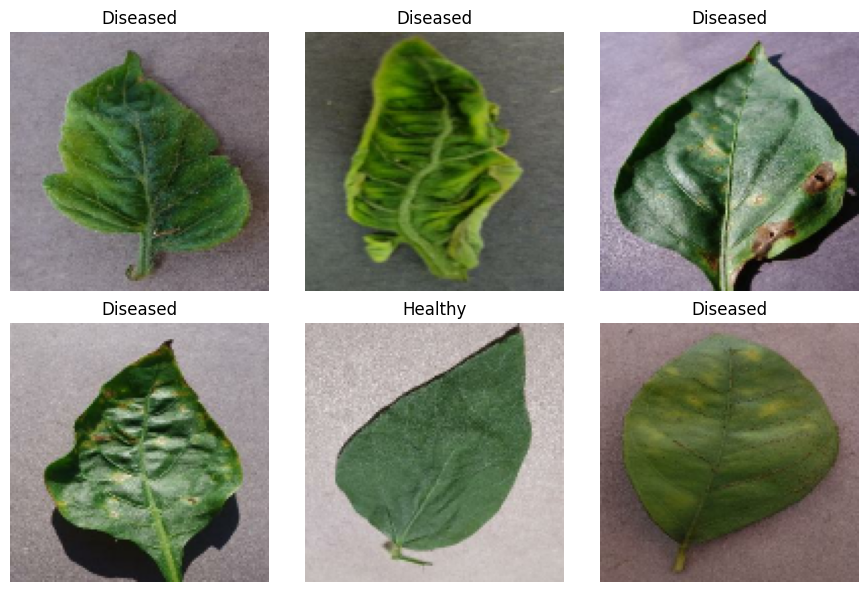

In [17]:
plt.figure(figsize=(9, 6))

for images, labels in train_ds.take(1):
    for i in range(6):
        plt.subplot(2, 3, i + 1)

        plt.imshow(
            tf.cast(images[i], tf.uint8)
        )

        label = int(labels[i].numpy())

        plt.title(
            "Healthy" if label == 1 else "Diseased"
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

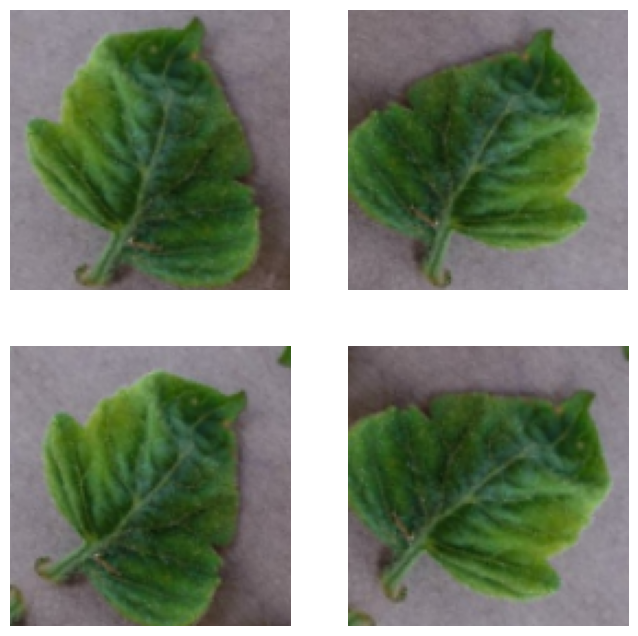

In [18]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15)
])

plt.figure(figsize=(8, 8))

for images, labels in train_ds.take(1):

    sample = images[:1]

    for i in range(4):

        augmented = data_augmentation(
            sample, training=True
        )

        plt.subplot(2, 2, i + 1)

        plt.imshow(
            tf.cast(
                tf.clip_by_value(augmented[0], 0, 255),
                tf.uint8
            )
        )

        plt.axis("off")

plt.show()

In [19]:
model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    layers.Conv2D(
        32, (3, 3), activation="relu"
    ),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(
        128, (3, 3), activation="relu"
    ),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [6]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [7]:
!pip install -q importlib_resources

import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix

print("Loading dataset...")
dataset, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names
healthy_ids = [
    i for i, name in enumerate(class_names)
    if "healthy" in name.lower()
]

def prepare_image(image, label):
    image = tf.image.resize(image, (128, 128))
    is_healthy = tf.reduce_any(tf.equal(label, healthy_ids))
    label = tf.cast(is_healthy, tf.float32)
    return image, label

total = info.splits["train"].num_examples
train_count = int(total * 0.70)
val_count = int(total * 0.15)

shuffled = dataset.shuffle(
    buffer_size=10000,
    seed=42,
    reshuffle_each_iteration=False
)

train_raw = shuffled.take(train_count)
remaining = shuffled.skip(train_count)
val_raw = remaining.take(val_count)
test_raw = remaining.skip(val_count)

AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32

train_ds = train_raw.map(prepare_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
val_ds = val_raw.map(prepare_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = test_raw.map(prepare_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15)
])

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Initialization complete! Variables, dataset, and model are now ready to train.")

Loading dataset...
Initialization complete! Variables, dataset, and model are now ready to train.


In [8]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)

Epoch 1/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1451s 1s/step - accuracy: 0.8844 - loss: 0.2562 - val_accuracy: 0.9371 - val_loss: 0.1579
Epoch 2/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9470 - loss: 0.1412

KeyboardInterrupt: 

In [9]:
model.save("plant_disease_cnn.keras")
print("Model saved successfully!")

Model saved successfully!


In [14]:
history_data = {
    "accuracy": [0.8844],
    "val_accuracy": [0.9371],
    "loss": [0.2562],
    "val_loss": [0.1579]
}

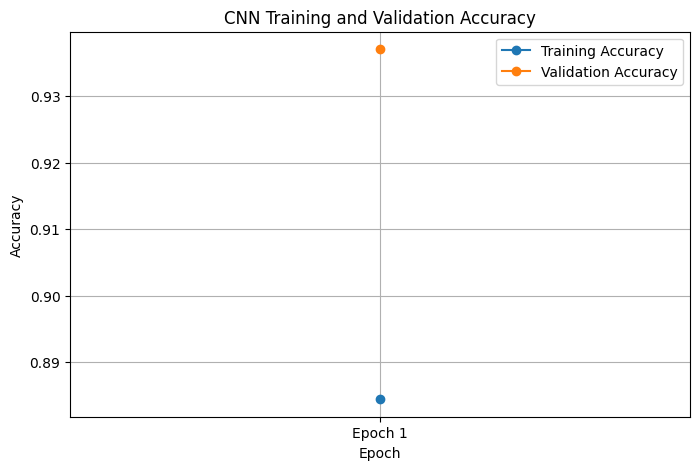

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history_data["accuracy"], marker="o",
         label="Training Accuracy")

plt.plot(history_data["val_accuracy"], marker="o",
         label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks([0], ["Epoch 1"])
plt.legend()
plt.grid()
plt.show()

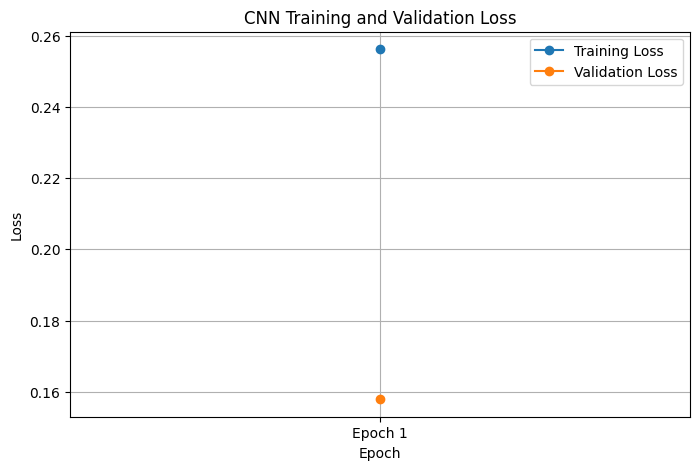

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(history_data["loss"], marker="o",
         label="Training Loss")

plt.plot(history_data["val_loss"], marker="o",
         label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks([0], ["Epoch 1"])
plt.legend()
plt.grid()
plt.show()

In [2]:
import os

print(os.listdir("/content"))

['.config', 'plant_disease_cnn.keras', 'sample_data']


In [6]:
from tensorflow.keras.models import load_model

model = load_model("/content/plant_disease_cnn.keras")

print("Model loaded successfully!")

Model loaded successfully!


In [8]:
import tensorflow as tf
import tensorflow_datasets as tfds

# Safely load the test dataset if it is not defined in the current session
try:
    test_ds
except NameError:
    print("test_ds not found in memory. Loading and preparing dataset...")
    dataset, info = tfds.load(
        "plant_village",
        split="train",
        as_supervised=True,
        with_info=True
    )
    class_names = info.features["label"].names
    healthy_ids = [i for i, name in enumerate(class_names) if "healthy" in name.lower()]

    def prepare_image(image, label):
        image = tf.image.resize(image, (128, 128))
        is_healthy = tf.reduce_any(tf.equal(label, healthy_ids))
        return image, tf.cast(is_healthy, tf.float32)

    total = info.splits["train"].num_examples
    train_count = int(total * 0.70)
    val_count = int(total * 0.15)

    shuffled = dataset.shuffle(buffer_size=10000, seed=42, reshuffle_each_iteration=False)
    test_raw = shuffled.skip(train_count + val_count)

    AUTOTUNE = tf.data.AUTOTUNE
    test_ds = test_raw.map(prepare_image, num_parallel_calls=AUTOTUNE).batch(32).prefetch(AUTOTUNE)
    print("Dataset prepared successfully!")

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

test_ds not found in memory. Loading and preparing dataset...
Dataset prepared successfully!
255/255 ━━━━━━━━━━━━━━━━━━━━ 110s 305ms/step - accuracy: 0.9503 - loss: 0.1300
Test Loss: 0.1300394982099533
Test Accuracy: 95.0282335281372 %


In [10]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for images, labels in test_ds
]).astype(int)

predictions = model.predict(test_ds)

y_pred = (
    predictions.reshape(-1) >= 0.5
).astype(int)

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Diseased", "Healthy"],
        zero_division=0
    )
)

255/255 ━━━━━━━━━━━━━━━━━━━━ 104s 298ms/step
              precision    recall  f1-score   support

    Diseased       0.99      0.94      0.96      5893
     Healthy       0.86      0.98      0.92      2253

    accuracy                           0.95      8146
   macro avg       0.93      0.96      0.94      8146
weighted avg       0.96      0.95      0.95      8146



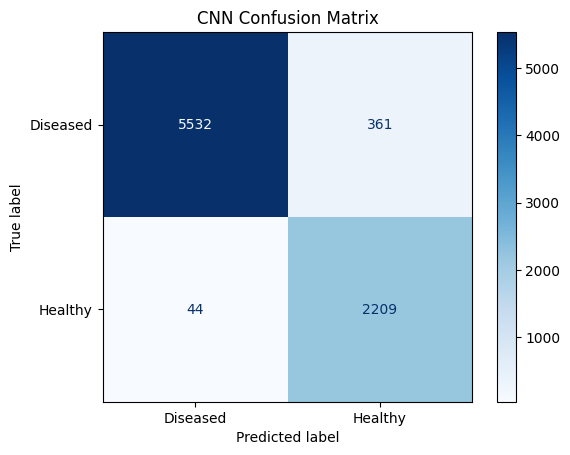

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Diseased", "Healthy"]
)

disp.plot(cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.show()

In [12]:
model.save("plant_disease_cnn.keras")

In [13]:
from google.colab import files

uploaded = files.upload()

Saving Healthy_vs_Diseased_Leaf_CNN.ipynb to Healthy_vs_Diseased_Leaf_CNN.ipynb
